In [2]:
#Import libraries
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras import layers, models


In [3]:
#Check TensorFlow version
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [4]:
#Set dataset path
dataset_path = r"D:\waste_classificatiob\Garbage_dataset\original"

In [5]:
#Define the 10 classes
class_names = [
    "battery",
    "biological",
    "cardboard",
    "clothes",
    "glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash"
]

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Number of classes: 10
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [6]:
#Check folders
for class_name in class_names:
    folder_path = os.path.join(dataset_path, class_name)

    if os.path.exists(folder_path):
        print("Found:", class_name)
    else:
        print("Missing:", class_name)

Found: battery
Found: biological
Found: cardboard
Found: clothes
Found: glass
Found: metal
Found: paper
Found: plastic
Found: shoes
Found: trash


In [7]:
#Count images in every class
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = {}

for class_name in class_names:
    folder_path = os.path.join(dataset_path, class_name)

    count = 0

    for file_name in os.listdir(folder_path):
        if file_name.lower().endswith(image_extensions):
            count += 1

    class_counts[class_name] = count

class_counts

{'battery': 756,
 'biological': 699,
 'cardboard': 1411,
 'clothes': 1892,
 'glass': 1736,
 'metal': 930,
 'paper': 1336,
 'plastic': 1597,
 'shoes': 1449,
 'trash': 453}

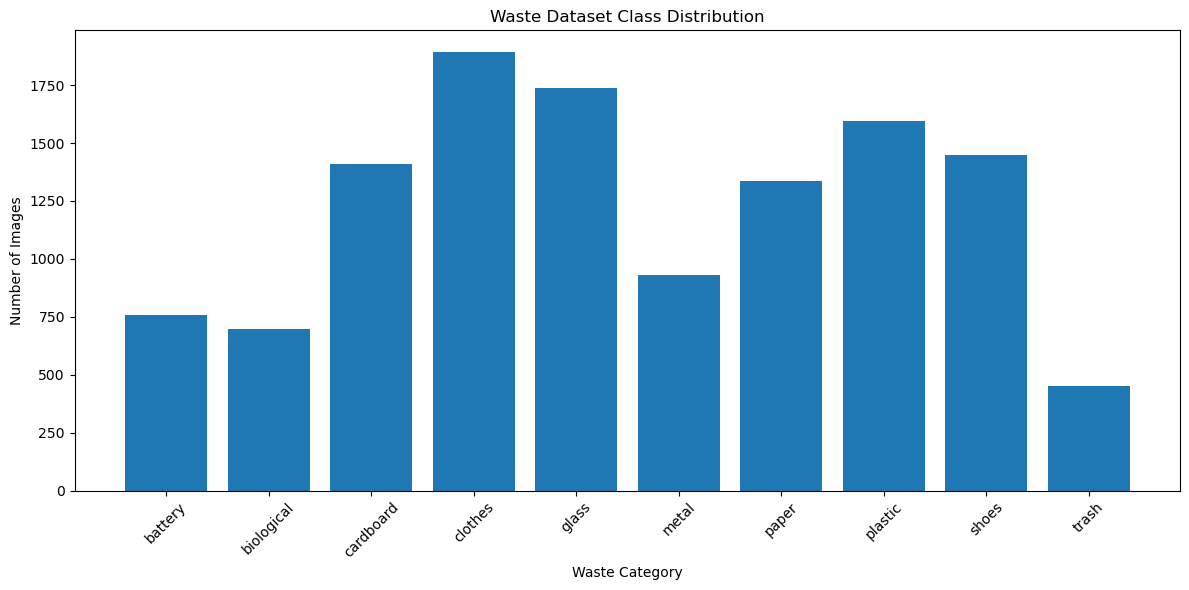

In [8]:
#Display class distribution
plt.figure(figsize=(12, 6))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Waste Dataset Class Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [9]:
#Display number of images
total_images = sum(class_counts.values())

print("Total number of images:", total_images)

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Total number of images: 12259
battery: 756
biological: 699
cardboard: 1411
clothes: 1892
glass: 1736
metal: 930
paper: 1336
plastic: 1597
shoes: 1449
trash: 453


In [10]:
#Find all image paths
image_paths = []
image_labels = []

for label, class_name in enumerate(class_names):

    folder_path = os.path.join(dataset_path, class_name)

    for file_name in os.listdir(folder_path):

        if file_name.lower().endswith(image_extensions):

            file_path = os.path.join(folder_path, file_name)

            image_paths.append(file_path)
            image_labels.append(label)

print("Total images found:", len(image_paths))
print("Total labels:", len(image_labels))

Total images found: 12259
Total labels: 12259


In [11]:
#Create a DataFrame
data = pd.DataFrame({
    "image_path": image_paths,
    "label": image_labels
})

data["class_name"] = data["label"].apply(
    lambda x: class_names[x]
)

data.head()

,image_path,label,class_name
0,D:\waste_classificatiob\Garbage_dataset\origin...,0,battery
1,D:\waste_classificatiob\Garbage_dataset\origin...,0,battery
2,D:\waste_classificatiob\Garbage_dataset\origin...,0,battery
3,D:\waste_classificatiob\Garbage_dataset\origin...,0,battery
4,D:\waste_classificatiob\Garbage_dataset\origin...,0,battery


In [12]:
#Check the dataset
print("Dataset shape:", data.shape)

print("\nClass distribution:")
print(data["class_name"].value_counts())

Dataset shape: (12259, 3)

Class distribution:
class_name
clothes       1892
glass         1736
plastic       1597
shoes         1449
cardboard     1411
paper         1336
metal          930
battery        756
biological     699
trash          453
Name: count, dtype: int64


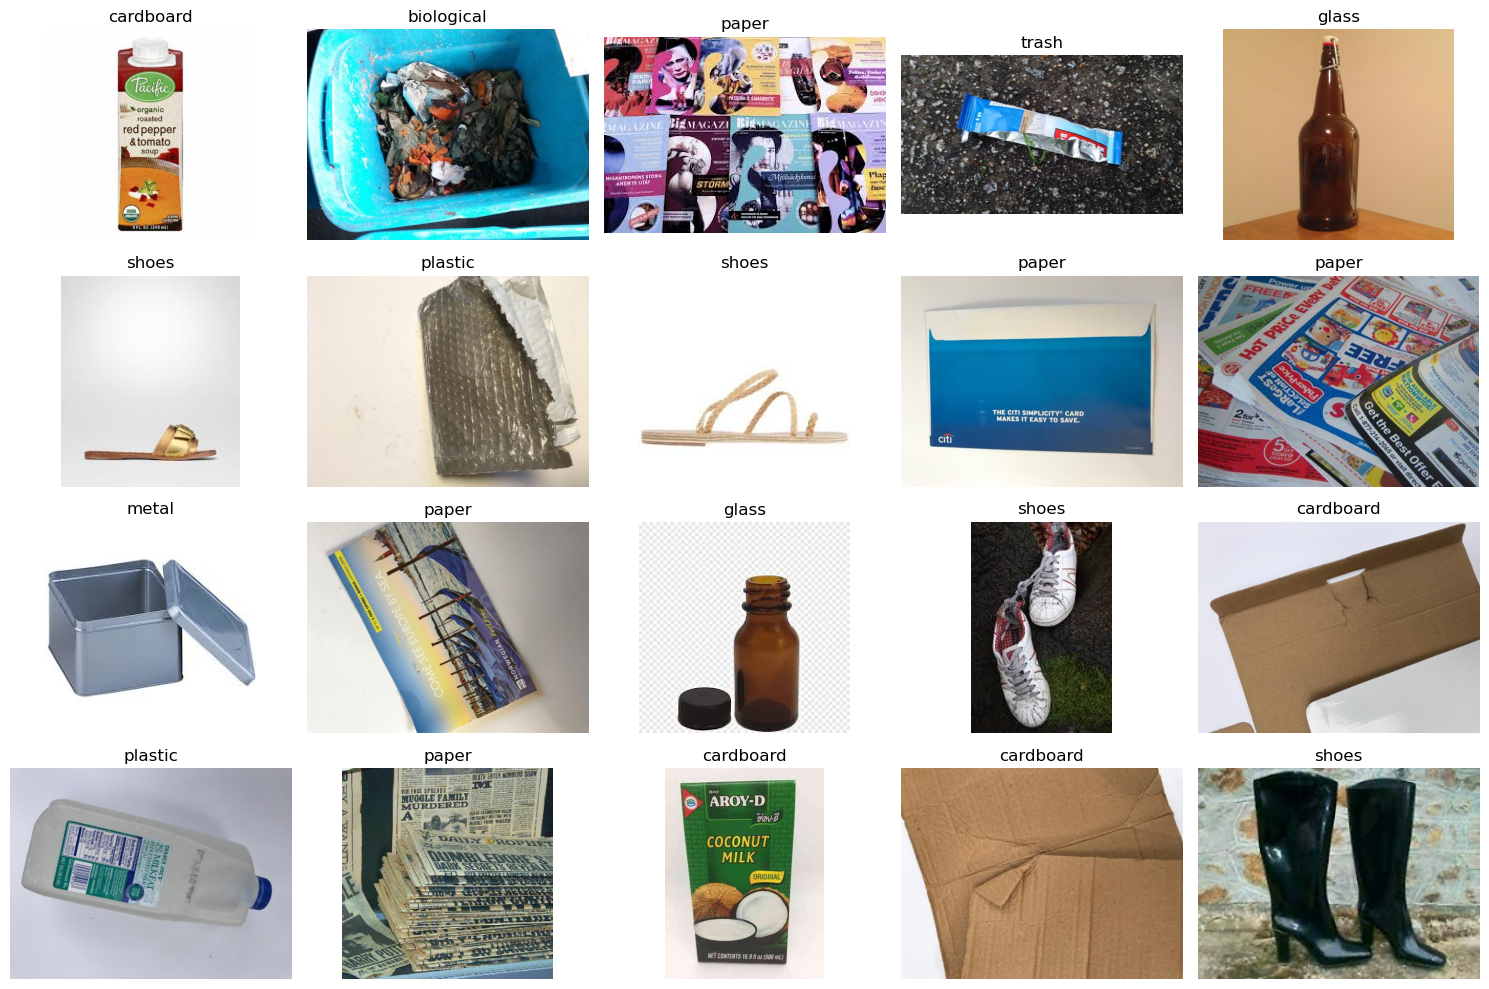

In [13]:
#Display sample images
plt.figure(figsize=(15, 10))

sample_data = data.sample(20, random_state=42)

for i, (_, row) in enumerate(sample_data.iterrows()):

    image = cv2.imread(row["image_path"])

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(4, 5, i + 1)

    plt.imshow(image)
    plt.title(row["class_name"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
#Check one image before preprocessing
sample_path = image_paths[1]

original_image = cv2.imread(sample_path)

print("Image path:", sample_path)
print("Original image shape:", original_image.shape)
print("Minimum pixel value:", original_image.min())
print("Maximum pixel value:", original_image.max())

Image path: D:\waste_classificatiob\Garbage_dataset\original\battery\battery_10.jpg
Original image shape: (194, 259, 3)
Minimum pixel value: 0
Maximum pixel value: 255


In [15]:
#Image preprocessing
IMAGE_SIZE = 160

def preprocess_image(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))

    # Keep pixel values between 0 and 1
    image = image.astype(np.float32) / 255.0

    return image


In [16]:
#Test preprocessing
processed_image = preprocess_image(sample_path)

print("Processed image shape:", processed_image.shape)

print("Minimum pixel value after normalization:", processed_image.min())
print("Maximum pixel value after normalization:", processed_image.max())

Processed image shape: (160, 160, 3)
Minimum pixel value after normalization: 0.0
Maximum pixel value after normalization: 1.0


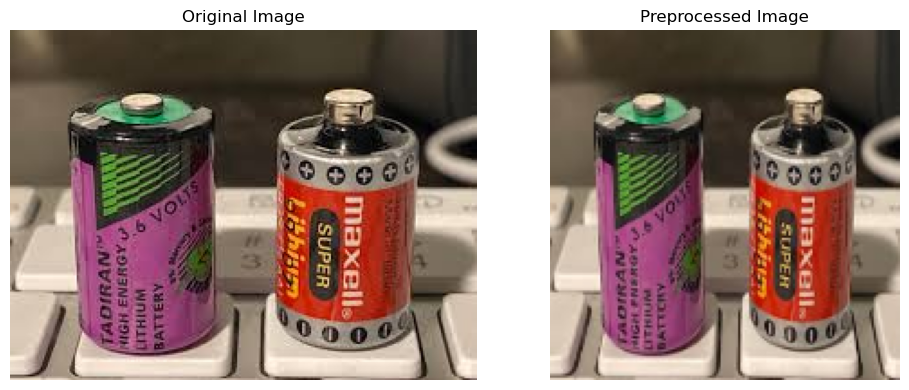

In [17]:
#Show original and processed image
original = cv2.imread(sample_path)

original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

processed = preprocess_image(sample_path)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)

plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)

plt.imshow(processed)
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
#Split dataset
train_data, temp_data = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data["label"]
)

validation_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42,
    stratify=temp_data["label"]
)

print("Training images:", len(train_data))
print("Validation images:", len(validation_data))
print("Testing images:", len(test_data))

Training images: 8581
Validation images: 1839
Testing images: 1839


In [19]:
#Check class distribution after splitting
print("Training distribution:")
print(train_data["class_name"].value_counts())

print("\nValidation distribution:")
print(validation_data["class_name"].value_counts())

print("\nTesting distribution:")
print(test_data["class_name"].value_counts())

Training distribution:
class_name
clothes       1325
glass         1215
plastic       1118
shoes         1014
cardboard      988
paper          935
metal          651
battery        529
biological     489
trash          317
Name: count, dtype: int64

Validation distribution:
class_name
clothes       283
glass         260
plastic       239
shoes         218
cardboard     212
paper         201
metal         139
battery       114
biological    105
trash          68
Name: count, dtype: int64

Testing distribution:
class_name
clothes       284
glass         261
plastic       240
shoes         217
cardboard     211
paper         200
metal         140
battery       113
biological    105
trash          68
Name: count, dtype: int64


In [20]:
#Create TensorFlow dataset
def load_and_preprocess(path, label):

    def process_image(path_string):

        path_string = path_string.decode("utf-8")

        image = preprocess_image(path_string)

        return image.astype(np.float32)

    image = tf.numpy_function(
        process_image,
        [path],
        tf.float32
    )

    image.set_shape((IMAGE_SIZE, IMAGE_SIZE, 3))

    return image, label

In [21]:
#Function to create dataset
BATCH_SIZE = 32

def create_dataset(dataframe, shuffle=False):

    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_and_preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

In [22]:
#Create train, validation and test datasets
train_dataset = create_dataset(
    train_data,
    shuffle=True
)

validation_dataset = create_dataset(
    validation_data,
    shuffle=False
)

test_dataset = create_dataset(
    test_data,
    shuffle=False
)

In [23]:
#Check one batch
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

    print("First 10 labels:",
          labels[:10].numpy())

Image batch shape: (32, 160, 160, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 labels: [7 8 4 4 5 7 4 7 6 1]


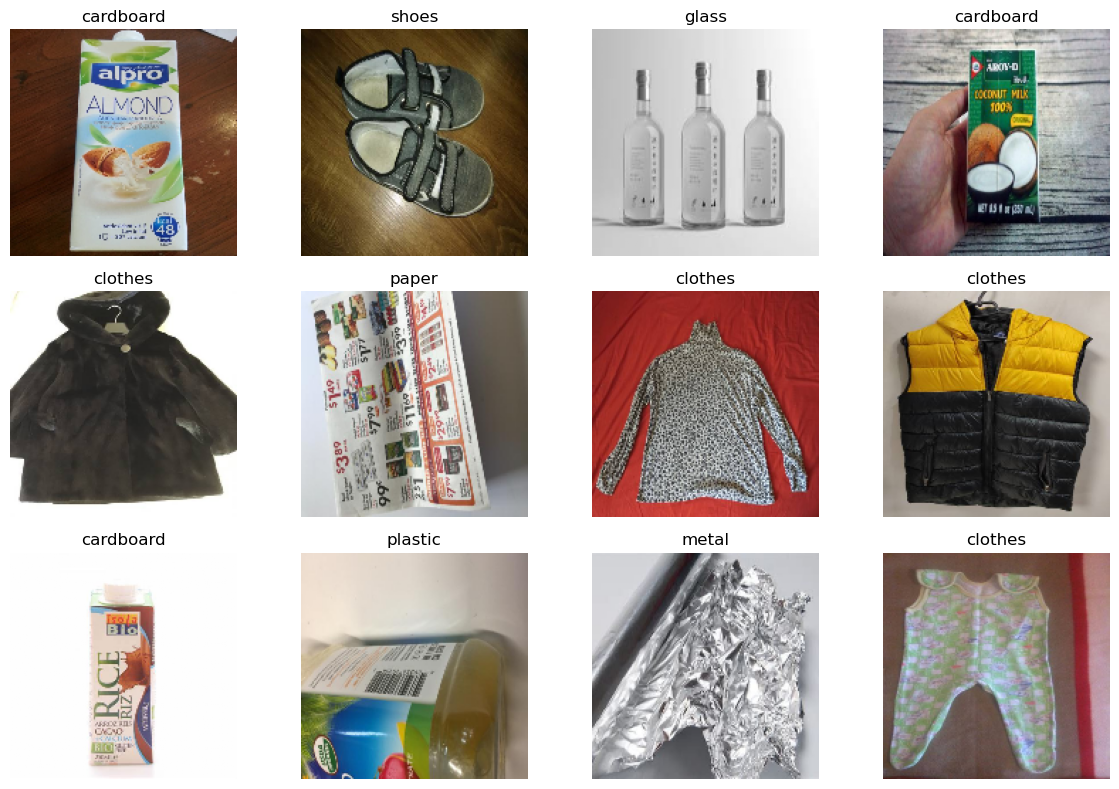

In [24]:
#Display preprocessed training images
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i])

        plt.title(class_names[labels[i].numpy()])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
#Calculate class weights
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_data["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_data["label"]
)

class_weights = dict(
    zip(classes, weights)
)

print("Class weights:")

for class_id, weight in class_weights.items():

    print(
        class_names[class_id],
        ":", 
        round(weight, 3)
    )

Class weights:
battery : 1.622
biological : 1.755
cardboard : 0.869
clothes : 0.648
glass : 0.706
metal : 1.318
paper : 0.918
plastic : 0.768
shoes : 0.846
trash : 2.707


In [26]:
# Transfer learning using MobileNetV2

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers 
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    # MobileNetV2 expects values in [-1, 1]
    layers.Rescaling(scale=2.0, offset=-1.0),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.35),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),

    layers.Dense(len(class_names), activation="softmax")
])

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 98s 10us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)             │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
#CELL 27 — Display CNN model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)             │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [28]:
#Compile model

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [29]:
#Train the model

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

EPOCHS = 25

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr]
) 

Epoch 1/25


C:\Users\ragha\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


269/269 ━━━━━━━━━━━━━━━━━━━━ 40s 134ms/step - accuracy: 0.6991 - loss: 0.9198 - val_accuracy: 0.8744 - val_loss: 0.3829 - learning_rate: 0.0010
Epoch 2/25
269/269 ━━━━━━━━━━━━━━━━━━━━ 36s 129ms/step - accuracy: 0.8130 - loss: 0.5603 - val_accuracy: 0.8847 - val_loss: 0.3269 - learning_rate: 0.0010
Epoch 3/25
269/269 ━━━━━━━━━━━━━━━━━━━━ 42s 151ms/step - accuracy: 0.8373 - loss: 0.4919 - val_accuracy: 0.8853 - val_loss: 0.3272 - learning_rate: 0.0010
Epoch 4/25
269/269 ━━━━━━━━━━━━━━━━━━━━ 40s 143ms/step - accuracy: 0.8532 - loss: 0.4233 - val_accuracy: 0.8961 - val_loss: 0.3008 - learning_rate: 0.0010
Epoch 5/25
269/269 ━━━━━━━━━━━━━━━━━━━━ 40s 145ms/step - accuracy: 0.8560 - loss: 0.4083 - val_accuracy: 0.9005 - val_loss: 0.2935 - learning_rate: 0.0010
Epoch 6/25
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 148ms/step - accuracy: 0.8651 - loss: 0.3796 - val_accuracy: 0.8967 - val_loss: 0.2855 - learning_rate: 0.0010
Epoch 7/25
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 149ms/step - accuracy: 0.8671 - loss:

In [30]:
#Fine-tuning

base_model.trainable = True

# Freeze most layers; fine-tuning only the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr]
)


Epoch 1/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 57s 154ms/step - accuracy: 0.9049 - loss: 0.2535 - val_accuracy: 0.9092 - val_loss: 0.2593 - learning_rate: 1.0000e-05
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 50s 182ms/step - accuracy: 0.9187 - loss: 0.2269 - val_accuracy: 0.9125 - val_loss: 0.2533 - learning_rate: 1.0000e-05
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 45s 162ms/step - accuracy: 0.9154 - loss: 0.2296 - val_accuracy: 0.9103 - val_loss: 0.2529 - learning_rate: 1.0000e-05
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 51s 185ms/step - accuracy: 0.9204 - loss: 0.2124 - val_accuracy: 0.9103 - val_loss: 0.2463 - learning_rate: 1.0000e-05
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 48s 172ms/step - accuracy: 0.9190 - loss: 0.2072 - val_accuracy: 0.9141 - val_loss: 0.2511 - learning_rate: 1.0000e-05
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.9286 - loss: 0.1998
Epoch 6: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
269/269 ━━━━━━━━━━━━━━━━━━━━ 52s 190ms/s

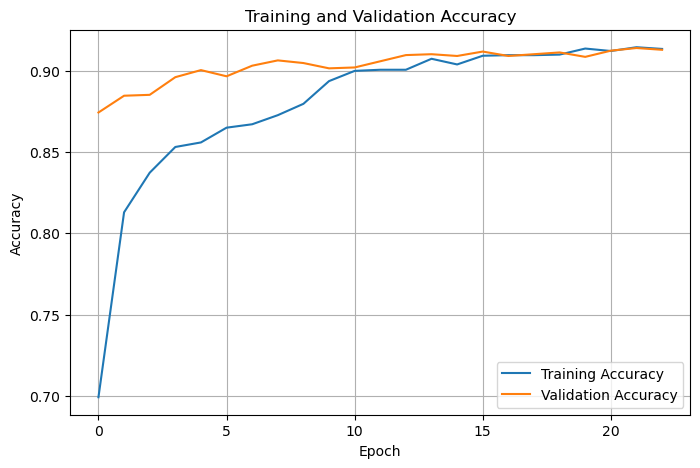

In [31]:
#Training accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

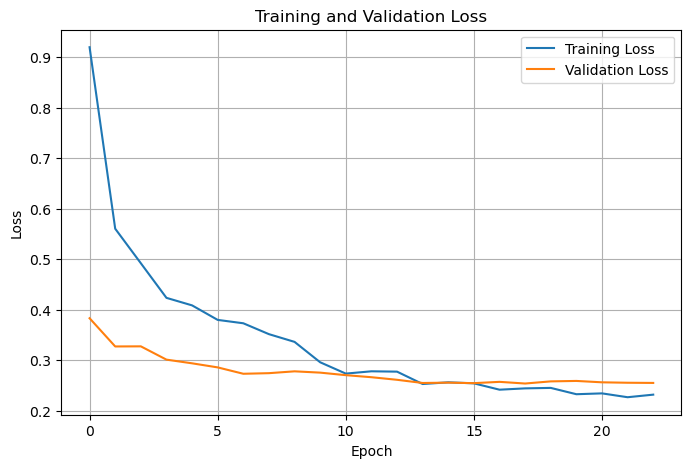

In [32]:
#Training loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [33]:
#Evaluate model on test data
test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print("Test Loss:", test_loss)

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

58/58 ━━━━━━━━━━━━━━━━━━━━ 9s 159ms/step - accuracy: 0.9108 - loss: 0.2645
Test Loss: 0.2644602656364441
Test Accuracy: 91.08 %


In [34]:
#Get predictions
y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_labels
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions completed.")

Predictions completed.


In [35]:
#Calculate accuracy
accuracy = accuracy_score(
    y_true,
    y_pred
)

print(
    "Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

Accuracy: 91.08 %


In [36]:
#Precision
precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    "Precision:",
    round(precision * 100, 2),
    "%"
)

Precision: 91.22 %


In [37]:
#Recall
recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    "Recall:",
    round(recall * 100, 2),
    "%"
)

Recall: 91.08 %


In [38]:
#F1-score
f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    "F1-score:",
    round(f1 * 100, 2),
    "%"
)

F1-score: 91.09 %


In [39]:
#Display all evaluation results
evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Score": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

evaluation_results["Score"] = evaluation_results["Score"].round(2)

evaluation_results

,Metric,Score
0,Accuracy,91.08
1,Precision,91.22
2,Recall,91.08
3,F1-Score,91.09


In [40]:
#Classification report
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     battery       0.99      0.88      0.93       113
  biological       0.98      0.96      0.97       105
   cardboard       0.93      0.93      0.93       211
     clothes       0.97      0.99      0.98       284
       glass       0.89      0.86      0.87       261
       metal       0.78      0.91      0.84       140
       paper       0.88      0.89      0.88       200
     plastic       0.86      0.82      0.84       240
       shoes       0.98      0.99      0.98       217
       trash       0.83      0.81      0.82        68

    accuracy                           0.91      1839
   macro avg       0.91      0.90      0.91      1839
weighted avg       0.91      0.91      0.91      1839



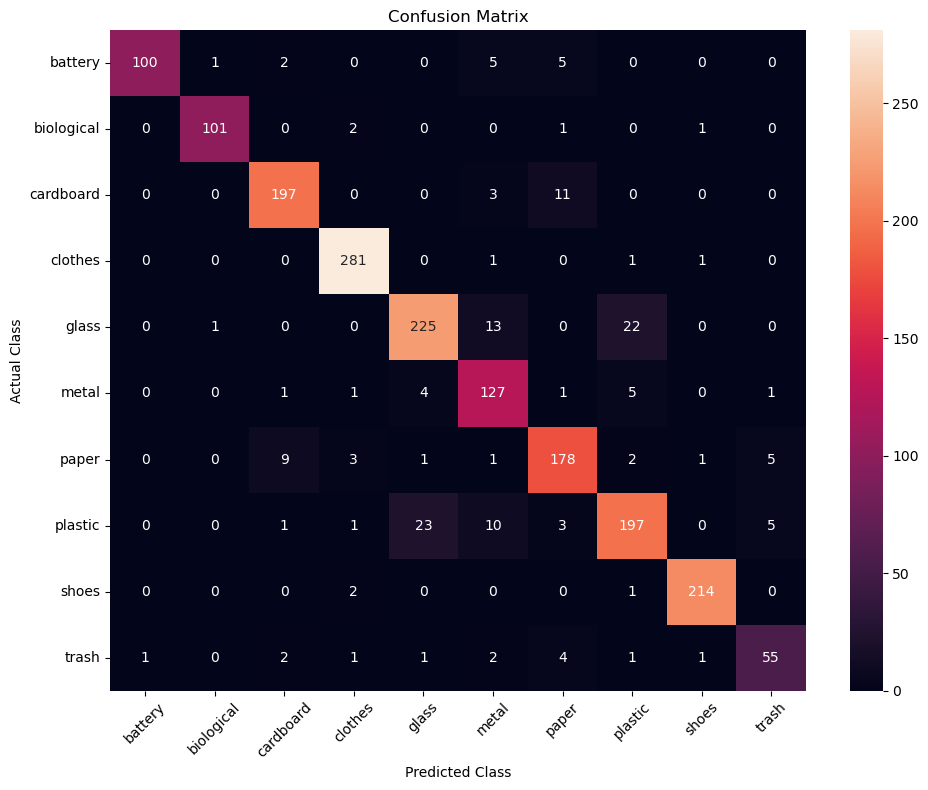

In [41]:
#Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.xticks(rotation=45)

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [43]:
#Save the trained model
model.save(
    "smart_waste_classifier.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [44]:
#Create disposal recommendations
recommendations = {

    "battery":
        "Dispose of batteries at a battery or e-waste collection center.",

    "biological":
        "Send biological waste for composting or proper biological waste treatment.",

    "cardboard":
        "Send cardboard for recycling. Keep it dry and clean if possible.",

    "clothes":
        "Reuse or donate clothes. If they cannot be reused, send them for textile recycling.",

    "glass":
        "Send glass waste to a glass recycling facility.",

    "metal":
        "Send metal waste to a metal recycling facility.",

    "paper":
        "Send paper waste for paper recycling.",

    "plastic":
        "Send plastic waste to a plastic recycling facility.",

    "shoes":
        "Reuse or donate shoes. If they cannot be reused, use an appropriate recycling facility.",

    "trash":
        "Dispose of general trash through the appropriate waste disposal system."
}

In [50]:
#Test unseen image
test_image_path = r"D:\waste_classificatiob\Garbage_dataset\my_test_images\battery.jpg"

In [51]:
#Prediction function
def predict_waste(image_path):

    # Read original image
    original = cv2.imread(image_path)

    if original is None:
        print("Image could not be loaded.")
        return

    # Convert for displaying
    display_image = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    # Preprocess image
    processed = preprocess_image(
        image_path
    )

    # Add batch dimension
    image_array = np.expand_dims(
        processed,
        axis=0
    )

    # Get prediction
    prediction = model.predict(
        image_array,
        verbose=0
    )[0]

    # Find class with highest probability
    predicted_index = np.argmax(
        prediction
    )

    predicted_class = class_names[
        predicted_index
    ]

    confidence = prediction[
        predicted_index
    ] * 100

    # Display image
    plt.figure(figsize=(6, 5))

    plt.imshow(display_image)

    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

    plt.show()

    # Print results
    print(
        "Predicted Waste Category:",
        predicted_class
    )

    print(
        f"Confidence: {confidence:.2f}%"
    )

    print("\nRecommendation:")

    print(
        recommendations[predicted_class]
    )

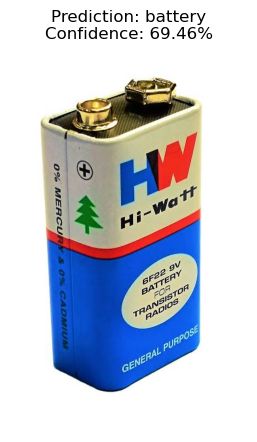

Predicted Waste Category: battery
Confidence: 69.46%

Recommendation:
Dispose of batteries at a battery or e-waste collection center.


In [52]:
#Run prediction
test_image_path = r"D:\waste_classificatiob\Garbage_dataset\my_test_images\battery.jpg"

predict_waste(test_image_path)

In [53]:
#Show probability for all classes
def show_all_probabilities(image_path):

    processed = preprocess_image(
        image_path
    )

    image_array = np.expand_dims(
        processed,
        axis=0
    )

    prediction = model.predict(
        image_array,
        verbose=0
    )[0]

    probability_data = pd.DataFrame({
        "Waste Category": class_names,
        "Probability (%)": prediction * 100
    })

    probability_data = probability_data.sort_values(
        "Probability (%)",
        ascending=False
    )

    probability_data["Probability (%)"] = (
        probability_data["Probability (%)"]
        .round(2)
    )

    print(probability_data)

    plt.figure(figsize=(10, 5))

    plt.bar(
        probability_data["Waste Category"],
        probability_data["Probability (%)"]
    )

    plt.title(
        "Prediction Probability for Each Waste Category"
    )

    plt.xlabel("Waste Category")

    plt.ylabel("Probability (%)")

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

  Waste Category  Probability (%)
0        battery        69.459999
2      cardboard        22.600000
5          metal         5.840000
6          paper         0.980000
7        plastic         0.950000
9          trash         0.110000
4          glass         0.060000
3        clothes         0.000000
8          shoes         0.000000
1     biological         0.000000


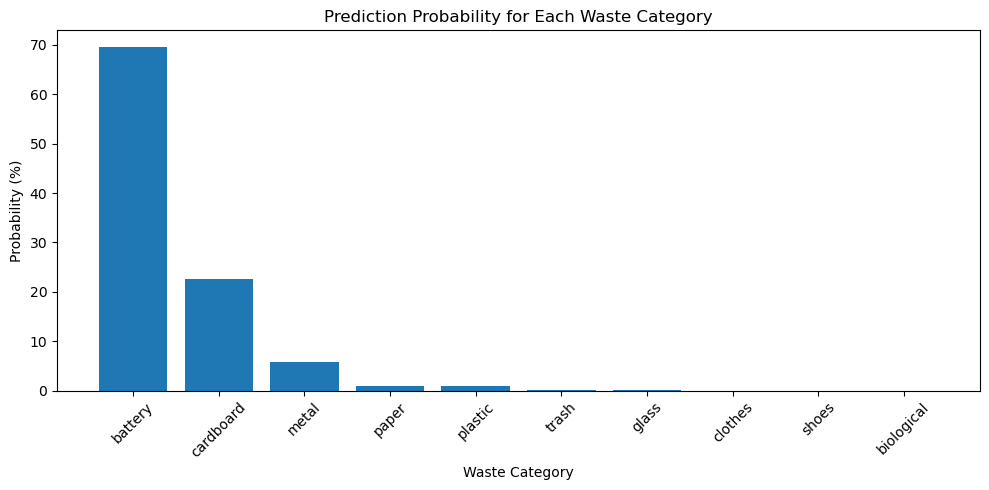

In [54]:
#Run probability analysis
show_all_probabilities(
    test_image_path
)

In [55]:
#Create a simple final prediction function
def classify_waste(image_path):

    processed = preprocess_image(
        image_path
    )

    image_array = np.expand_dims(
        processed,
        axis=0
    )

    prediction = model.predict(
        image_array,
        verbose=0
    )[0]

    predicted_index = np.argmax(
        prediction
    )

    category = class_names[
        predicted_index
    ]

    confidence = prediction[
        predicted_index
    ] * 100

    print("=" * 50)

    print("SMART WASTE CLASSIFICATION SYSTEM")

    print("=" * 50)

    print(
        "Waste Category:",
        category
    )

    print(
        f"Confidence: {confidence:.2f}%"
    )

    print("\nRecommended Action:")

    print(
        recommendations[category]
    )

    print("=" * 50)

In [56]:
#Final demonstration
classify_waste(test_image_path)

SMART WASTE CLASSIFICATION SYSTEM
Waste Category: battery
Confidence: 69.46%

Recommended Action:
Dispose of batteries at a battery or e-waste collection center.


In [57]:
#Load saved model later
from tensorflow.keras.models import load_model

loaded_model = load_model(
    "smart_waste_classifier.keras"
)

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [58]:
#Check that loaded model works
processed = preprocess_image(
    test_image_path
)

image_array = np.expand_dims(
    processed,
    axis=0
)

prediction = loaded_model.predict(
    image_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

print(
    "Predicted class:",
    class_names[predicted_index]
)

print(
    "Confidence:",
    round(
        prediction[0][predicted_index] * 100,
        2
    ),
    "%"
)

Predicted class: battery
Confidence: 69.46 %
